# Trabajo Práctico 1. Visión por Computadora I

Posgrado en Inteligencia Artificial, FIUBA. Docente: Ing. Maxim Dorogov.

Integrantes: Florencia Lucca, Carlos Lugones, Mariano Reimondez.

Consigna:

Parte 1 (imágenes en `white_patch/`)
1. Implementar el algoritmo White Patch para librarnos de las diferencias de color de iluminación.
2. Mostrar los resultados obtenidos y analizar las posibles fallas (si es que las hay) en el caso de White Patch.

Parte 2
1. Para las imágenes `img1_tp.png` y `img2_tp.png`, leerlas con OpenCV en escala de grises y visualizarlas.
2. Elegir el número de bins que se crea conveniente y graficar su histograma, comparar los histogramas entre sí. Explicar lo que se observa. Si tuviera que entrenar un modelo de clasificación o detección de imágenes, ¿considera que puede ser de utilidad tomar como features a los histogramas?

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGENES = Path("imagenes")
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)


def leer(ruta, flag=cv2.IMREAD_COLOR):
    img = cv2.imread(str(ruta), flag)
    if img is None:
        raise FileNotFoundError(f"No se encontró {ruta}. El notebook debe ejecutarse desde la carpeta TP1.")
    return img


def leer_rgb(ruta):
    # OpenCV lee en orden BGR; se pasa a RGB para trabajar y graficar con matplotlib
    return cv2.cvtColor(leer(ruta), cv2.COLOR_BGR2RGB)

## Parte 1. White Patch

El algoritmo supone que en la escena hay una superficie blanca, o al menos acromática, que es la más brillante de cada canal, y que la escena está iluminada por una sola luz aproximadamente uniforme. Bajo una luz de color, esa superficie deja de verse blanca: el máximo de cada canal queda por debajo de 255 en una proporción que depende del color de la luz. La corrección consiste en reescalar cada canal por separado para que su máximo vuelva a 255:

$$R' = \frac{255}{R_{max}}\,R \qquad G' = \frac{255}{G_{max}}\,G \qquad B' = \frac{255}{B_{max}}\,B$$

Reescalar cada canal con un factor propio equivale a modelar el efecto del iluminante como una ganancia multiplicativa por canal (modelo diagonal de von Kries). Bajo ese modelo, si la superficie de referencia es gris en lugar de blanca, el balance de color se corrige igual y solo cambia el brillo general. Lo que sí rompe el método es que lo más brillante de un canal sea una superficie de color: el factor queda sesgado aunque no haya ningún píxel saturado.

Si un canal ya tiene píxeles en 255, el factor vale 1 y ese canal no cambia. Para que unos pocos píxeles saturados no definan la referencia, el máximo se reemplaza por un percentil alto (99 o 98). Esto funciona solo mientras la fracción de píxeles saturados del canal sea menor que la cola que descarta el percentil (1 % con p=99, 2 % con p=98); si es mayor, el percentil también vale 255 y el canal queda igual que con el máximo. Un percentil más bajo agranda el factor y satura más píxeles, con la consiguiente pérdida de información.

In [2]:
def white_patch(img, p=100):
    """Aplica White Patch a una imagen RGB uint8.

    p=100 usa el máximo de cada canal como referencia de blanco;
    p<100 usa ese percentil, que evita que unos pocos píxeles saturados fijen
    la referencia; sirve mientras sean menos del (100 - p) % del canal.
    """
    img_f = img.astype(np.float32)
    ref = np.percentile(img_f, p, axis=(0, 1))   # referencia por canal (R, G, B)
    ref = np.maximum(ref, 1)                      # un canal completamente apagado no se escala
    out = img_f * (255.0 / ref)
    return np.clip(out, 0, 255).astype(np.uint8)

### Imágenes de prueba (`test_*`)

Tres fotos de la misma escena con luz azul, verde y roja.

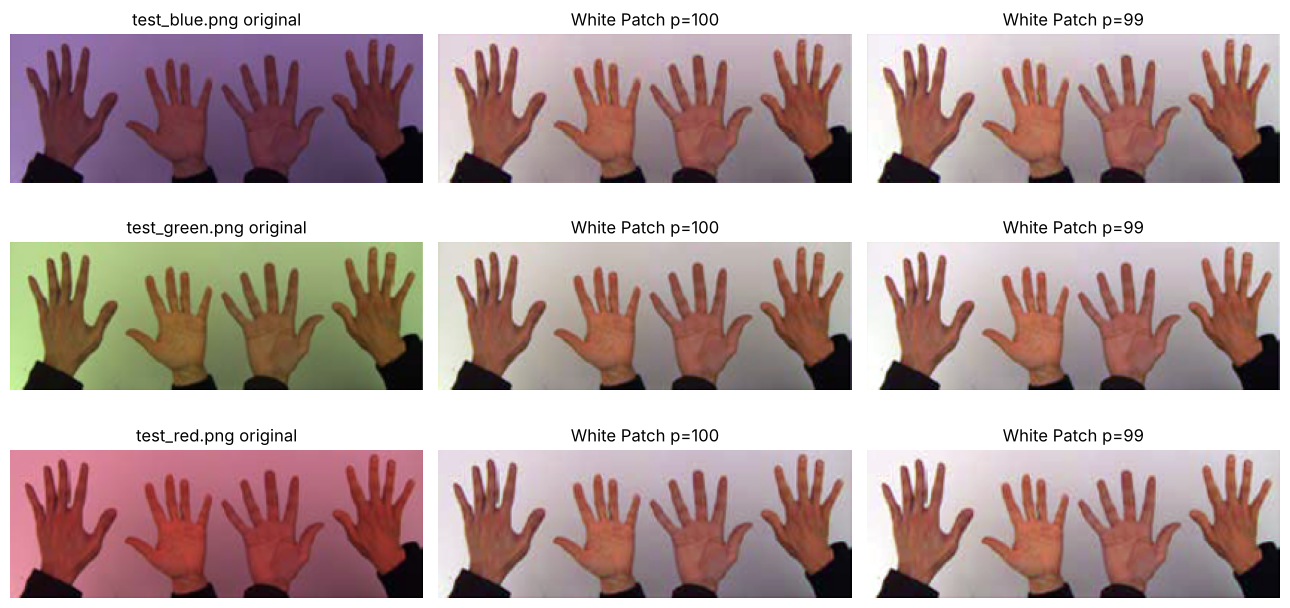

In [3]:
tests = sorted((IMAGENES / "white_patch").glob("test_*"))
ps_test = [100, 99]

fig, ax = plt.subplots(len(tests), 1 + len(ps_test), figsize=(13, 2.2 * len(tests)))
for i, f in enumerate(tests):
    im = leer_rgb(f)
    ax[i, 0].imshow(im)
    ax[i, 0].set_title(f"{f.name} original")
    for j, p in enumerate(ps_test, start=1):
        ax[i, j].imshow(white_patch(im, p))
        ax[i, j].set_title(f"White Patch p={p}")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGURAS / "white_patch_test.png", dpi=100, bbox_inches="tight")
plt.show()

### Imágenes con iluminación real (`wp_*`)

La misma figura iluminada con luces de color intensas. Se compara el máximo (p=100) con los percentiles 99 y 98.

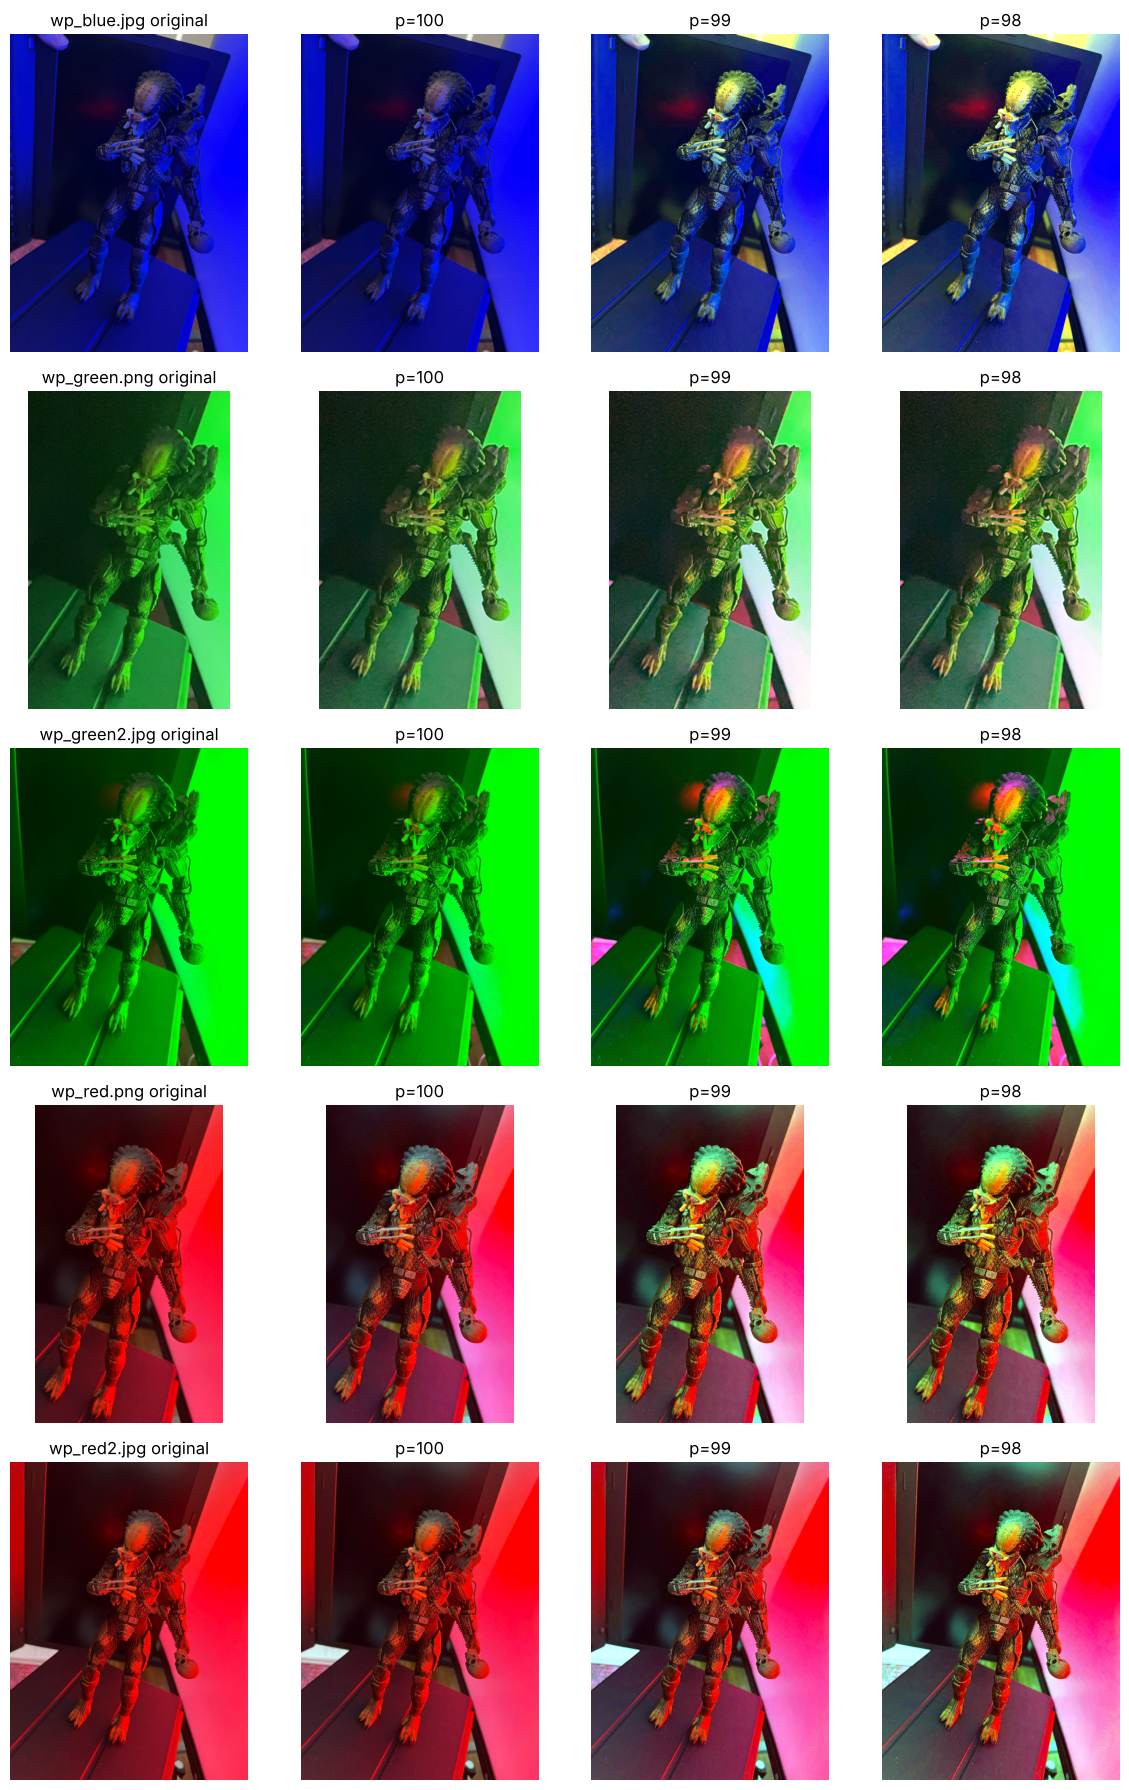

In [4]:
reales = sorted((IMAGENES / "white_patch").glob("wp_*"))
ps_real = [100, 99, 98]

fig, ax = plt.subplots(len(reales), 1 + len(ps_real), figsize=(12, 3.6 * len(reales)))
for i, f in enumerate(reales):
    im = leer_rgb(f)
    ax[i, 0].imshow(im)
    ax[i, 0].set_title(f"{f.name} original")
    for j, p in enumerate(ps_real, start=1):
        ax[i, j].imshow(white_patch(im, p))
        ax[i, j].set_title(f"p={p}")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGURAS / "white_patch_reales.png", dpi=70, bbox_inches="tight")
plt.show()

### Valores de referencia por canal

Para cada imagen: el máximo y el percentil 99 de cada canal, el factor que resulta con p=99, el porcentaje de píxeles con algún canal en 255 antes y después de la corrección, y la media por canal antes y después.

In [5]:
def pct_saturado(img):
    return 100 * np.mean((img == 255).any(axis=-1))

def fmt(v, d=0):
    return "[" + ", ".join(f"{x:.{d}f}" for x in v) + "]"

print(f"{'imagen':15s}{'máx RGB':>17s}{'p99 RGB':>17s}{'factor p99':>20s}{'% sat. orig':>12s}{'% sat. p99':>11s}{'media orig':>17s}{'media p99':>17s}")
for f in tests + reales:
    im = leer_rgb(f)
    wp = white_patch(im, 99)
    mx = im.reshape(-1, 3).max(axis=0)
    p99 = np.percentile(im, 99, axis=(0, 1))
    print(f"{f.name:15s}{fmt(mx):>17s}{fmt(p99):>17s}{fmt(255 / np.maximum(p99, 1), 2):>20s}"
          f"{pct_saturado(im):12.1f}{pct_saturado(wp):11.1f}"
          f"{fmt(im.reshape(-1, 3).mean(axis=0)):>17s}{fmt(wp.reshape(-1, 3).mean(axis=0)):>17s}")

imagen                   máx RGB          p99 RGB          factor p99 % sat. orig % sat. p99       media orig        media p99
test_blue.png    [165, 138, 200]  [153, 122, 180]  [1.67, 2.09, 1.42]         0.0        2.4   [103, 69, 101]  [171, 145, 142]
test_green.png   [210, 250, 171]  [193, 230, 150]  [1.32, 1.11, 1.70]         0.0        1.8   [129, 131, 84]  [170, 145, 142]
test_red.png     [247, 157, 175]  [230, 143, 163]  [1.11, 1.78, 1.56]         0.0        1.8    [156, 81, 91]  [172, 144, 142]
wp_blue.jpg      [255, 255, 255]   [117, 86, 254]  [2.18, 2.97, 1.00]         0.5        2.5    [18, 17, 121]    [37, 49, 122]


wp_green.png     [126, 252, 155]   [88, 244, 120]  [2.90, 1.05, 2.12]         0.0        3.5    [26, 103, 35]    [75, 107, 73]


wp_green2.jpg    [170, 255, 172]    [70, 255, 56]  [3.64, 1.00, 4.55]         5.1        6.8      [4, 126, 4]    [15, 126, 17]
wp_red.png       [255, 134, 122]   [255, 74, 102]  [1.00, 3.45, 2.50]         6.5        8.5    [123, 19, 25]    [123, 64, 63]


wp_red2.jpg      [255, 201, 203]  [255, 119, 119]  [1.00, 2.14, 2.14]         9.1       10.1    [129, 21, 30]    [129, 43, 62]


### Análisis de la Parte 1

En las imágenes `test_*` el algoritmo funciona como se espera. Ningún canal llega a 255 (los máximos van de 138 a 250), así que el máximo es una referencia válida y ya con p=100 desaparece el tinte: el fondo vuelve a verse gris claro y la piel recupera su tono. Las tres versiones corregidas quedan muy parecidas entre sí, y con p=99 las medias por canal prácticamente coinciden (alrededor de [171, 145, 142]) aunque las originales eran muy distintas. Esto muestra que la corrección es consistente frente al cambio de iluminante; no demuestra que se recuperen los colores reales de la escena, porque no hay una toma con luz neutra contra la cual comparar. Pasar de p=100 a p=99 casi no cambia el resultado y apenas satura alrededor de un 2 % de los píxeles.

En las imágenes `wp_*` aparecen las fallas:

1. Canales saturados. En `wp_blue.jpg` los tres canales tienen algún píxel en 255, los tres factores valen 1 y la salida con p=100 es idéntica a la entrada. Es el caso en que el máximo deja de servir y hay que pasar al percentil: con p=99 la referencia de R baja a 117 y la de G a 86, y la figura recupera parte de su color. En `wp_red.png`, `wp_red2.jpg` y `wp_green2.jpg` lo que se satura es el canal dominante, y en una fracción tan grande (6,5 %, 9,1 % y 5,1 % de los píxeles) que su percentil 99 y su percentil 98 siguen valiendo 255: la saturación supera la cola que descarta el percentil (1 % y 2 %), y la variante robusta deja de servir para ese canal. Ese canal queda fijo en todas las versiones y la corrección sale solo de amplificar los otros dos. Con p=100 esa amplificación es chica porque unos pocos píxeles brillantes fijan el máximo (en `wp_red2.jpg` los factores de G y B son 1,27); con p=99 suben a 2,14 y el efecto se nota.

2. No hay un blanco en la escena. Lo más brillante de cada canal es la pared iluminada directamente por la lámpara de color, no un objeto blanco. La hipótesis del algoritmo no se cumple y la corrección queda a mitad de camino: después de p=99 la media de `wp_green2.jpg` sigue siendo [15, 126, 17] y la de `wp_blue.jpg` [37, 49, 122], con el color de la luz todavía dominante.

3. Canales casi sin información. Cuando la luz es casi monocromática, los otros canales registran muy poca señal (en `wp_green2.jpg` R y B tienen media 4). Multiplicarlos por 3,6 y 4,6 no recupera un color que el sensor no captó; amplifica el ruido y los artefactos de compresión JPEG. Además, en los píxeles donde el canal dominante estaba en 255 el valor registrado subestima el real, y al amplificar solo los otros dos la proporción entre canales se desplaza. El resultado son colores espurios, producidos por la corrección y no por la escena, como las zonas magenta y cian de `wp_green2.jpg` o las manchas verdosas en las partes oscuras de `wp_red.png`.

4. El percentil tiene un costo. Todo lo que queda por encima de la referencia termina en 255, y esa saturación no se puede revertir. En `wp_blue.jpg` el porcentaje de píxeles saturados pasa de 0,5 % en el original a 2,5 % con p=99 y a 5,9 % con p=98; por eso no conviene bajar mucho más el percentil.

5. La corrección es global. Se aplica un único factor por canal a toda la imagen, lo que supone una sola fuente de luz uniforme. Si distintas zonas reciben luz de distinto color, ningún factor las corrige a todas.

En síntesis, White Patch compensa razonablemente la dominante de color de la iluminación cuando se cumplen sus supuestos: una superficie acromática que sea lo más brillante de la escena, una iluminación aproximadamente uniforme y canales sin saturación extensa, como en las `test_*`. Si lo más brillante es una superficie de color, los factores salen sesgados aunque no haya saturación, y con luces intensas y casi monocromáticas la corrección es parcial. El percentil 99 resuelve el caso de unos pocos píxeles saturados con poca pérdida, pero no el de un canal con más del 1 % de saturación, y bajar a 98 o menos ya satura demasiado.

## Parte 2. Histogramas

### Lectura y visualización

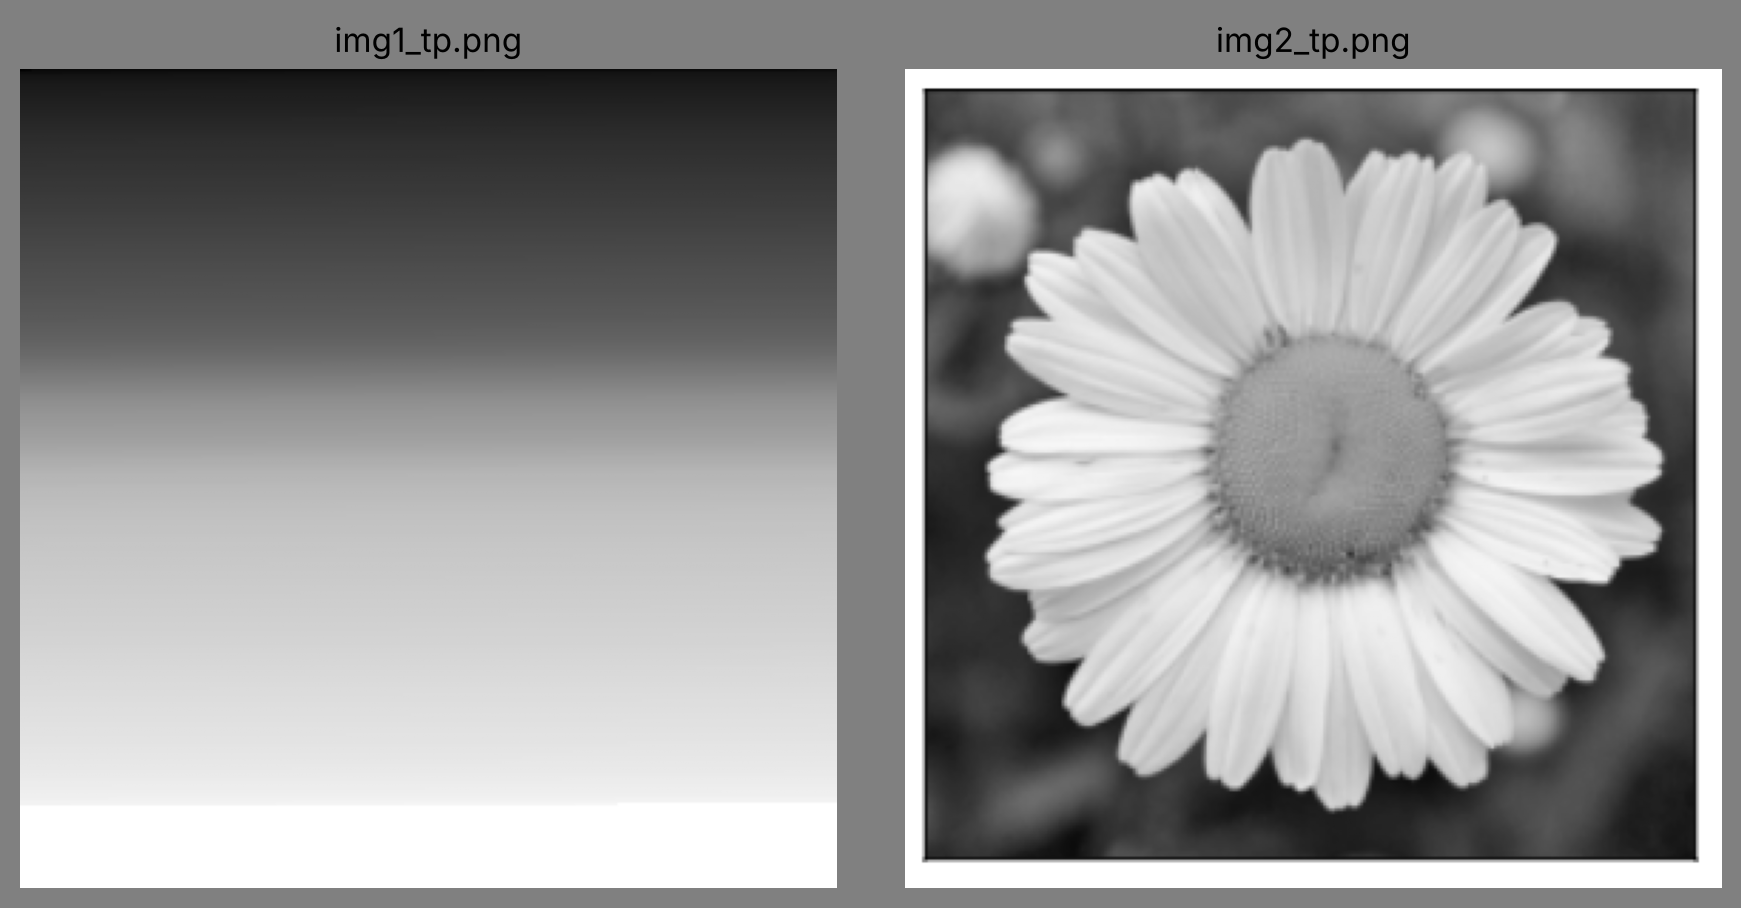

img1: (288, 287), uint8, mín 2, máx 255, media 154.8
img2: (288, 287), uint8, mín 2, máx 255, media 154.8
img2: 8400 píxeles en 255, de los cuales 0 están a más de 10 píxeles del borde


In [6]:
img1 = leer(IMAGENES / "img1_tp.png", cv2.IMREAD_GRAYSCALE)
img2 = leer(IMAGENES / "img2_tp.png", cv2.IMREAD_GRAYSCALE)

# fondo gris: sobre blanco no se verían los bordes blancos de las imágenes
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5), facecolor="gray")
for a, img, nombre in zip(ax, (img1, img2), ("img1_tp.png", "img2_tp.png")):
    a.imshow(img, cmap="gray", vmin=0, vmax=255)
    a.set_title(nombre)
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGURAS / "imagenes_grises.png", dpi=100, bbox_inches="tight")
plt.show()

for nombre, img in (("img1", img1), ("img2", img2)):
    print(f"{nombre}: {img.shape}, {img.dtype}, mín {img.min()}, máx {img.max()}, media {img.mean():.1f}")

print(f"img2: {(img2 == 255).sum()} píxeles en 255, de los cuales {(img2[10:-10, 10:-10] == 255).sum()} están a más de 10 píxeles del borde")

`img1_tp.png` es un degradé vertical, oscuro arriba y claro abajo, que termina en una franja blanca. `img2_tp.png` es una margarita sobre un fondo oscuro desenfocado y tiene un marco blanco de entre 6 y 9 píxeles alrededor. Sobre una página blanca ese marco no se distingue, por eso las imágenes se muestran sobre fondo gris. Todos los píxeles en 255 de `img2` (8400) están en ese borde: ninguno aparece a más de 10 píxeles de él. Las dos son de 288 x 287 píxeles.

### Elección del número de bins

Con 256 bins (uno por nivel de gris) cada bin recibe en promedio la cuarta parte de los píxeles que con 64, la representación es más granular y las diferencias entre niveles vecinos hacen que la curva quede irregular; con muy pocos bins se pierde la forma de la distribución. Se comparan tres opciones sobre `img2`:

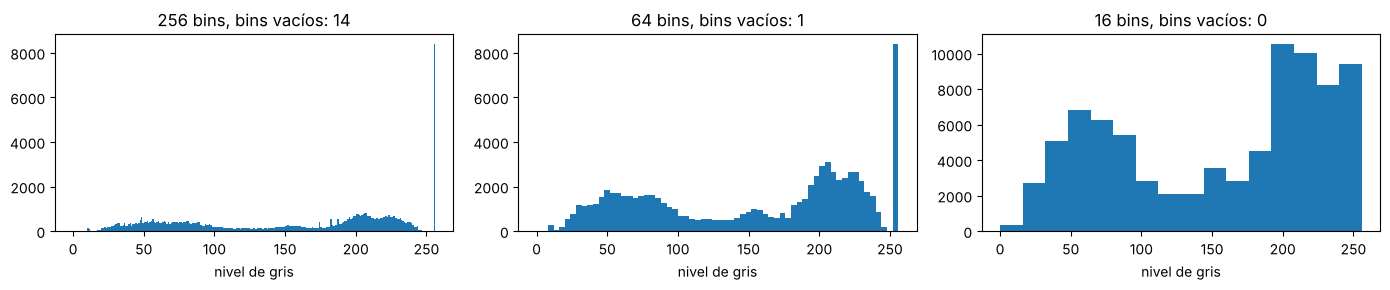

In [7]:
opciones = [256, 64, 16]
fig, ax = plt.subplots(1, len(opciones), figsize=(14, 3))
for a, b in zip(ax, opciones):
    h, bordes = np.histogram(img2, bins=b, range=(0, 256))
    a.bar(bordes[:-1], h, width=256 / b, align="edge")
    a.set_title(f"{b} bins, bins vacíos: {np.sum(h == 0)}")
    a.set_xlabel("nivel de gris")
plt.tight_layout()
plt.show()

Con 256 bins hay 14 niveles sin ningún píxel y el contorno es irregular. Con 16 bins cada barra agrupa 16 niveles y el pico en 255 queda mezclado con la cola de los pétalos (240 a 247), de modo que ya no se ve que se trata de un valor aislado. Se eligen 64 bins (4 niveles de gris por bin): la curva es continua, conserva los tres modos y el pico en 255 queda separado del resto por un bin vacío.

### Histogramas y comparación

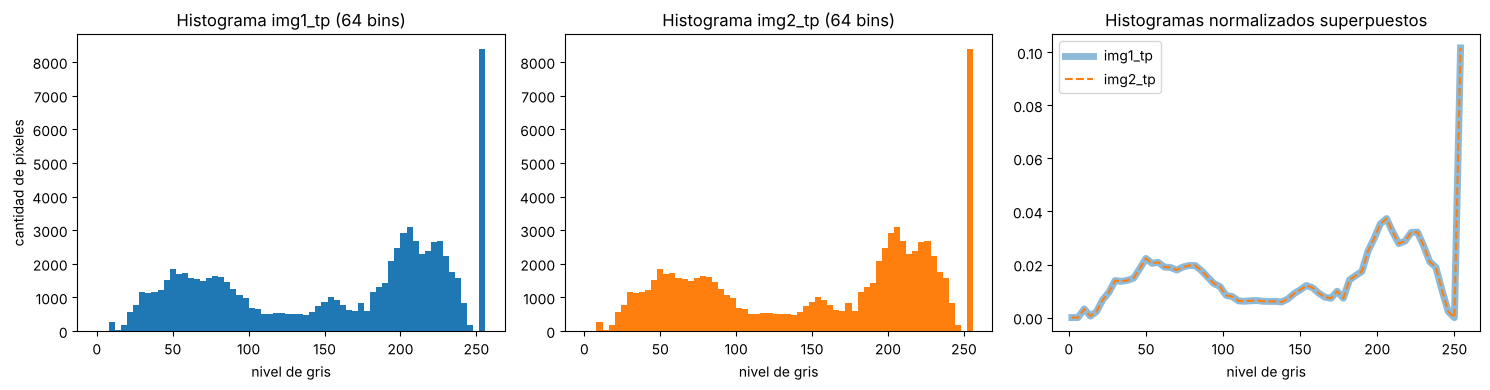

Correlación entre histogramas: 1.0
Mismos valores de píxel en ambas imágenes: True


In [8]:
BINS = 64

hists = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, (img, nombre, color) in enumerate(((img1, "img1_tp", "tab:blue"), (img2, "img2_tp", "tab:orange"))):
    h, bordes = np.histogram(img, bins=BINS, range=(0, 256))
    hists[nombre] = h / h.sum()
    ax[k].bar(bordes[:-1], h, width=256 / BINS, align="edge", color=color)
    ax[k].set_title(f"Histograma {nombre} ({BINS} bins)")
    estilo = {"lw": 5, "alpha": 0.5} if k == 0 else {"lw": 1.5, "ls": "--"}
    ax[2].plot(bordes[:-1] + 128 / BINS, hists[nombre], color=color, label=nombre, **estilo)
ax[2].set_title("Histogramas normalizados superpuestos")
ax[2].legend()
for a in ax:
    a.set_xlabel("nivel de gris")
ax[0].set_ylabel("cantidad de píxeles")
plt.tight_layout()
plt.savefig(FIGURAS / "histogramas.png", dpi=100, bbox_inches="tight")
plt.show()

h1 = hists["img1_tp"].astype(np.float32)
h2 = hists["img2_tp"].astype(np.float32)
print("Correlación entre histogramas:", round(cv2.compareHist(h1, h2, cv2.HISTCMP_CORREL), 6))
print("Mismos valores de píxel en ambas imágenes:", np.array_equal(np.sort(img1, axis=None), np.sort(img2, axis=None)))

Para contrastar con una medida que sí depende de la disposición espacial, se calcula el contraste local visto en clase: la imagen se divide en una grilla de 8 x 8, se calcula máximo menos mínimo en cada celda y se promedia.

In [9]:
def contraste_local(img, n=8):
    alto, ancho = img.shape
    valores = []
    for i in range(n):
        for j in range(n):
            celda = img[i * alto // n:(i + 1) * alto // n, j * ancho // n:(j + 1) * ancho // n]
            valores.append(int(celda.max()) - int(celda.min()))
    return np.mean(valores)

for nombre, img in (("img1", img1), ("img2", img2)):
    print(f"{nombre}: contraste global {int(img.max()) - int(img.min())}, contraste local {contraste_local(img):.1f}")

img1: contraste global 253, contraste local 30.1
img2: contraste global 253, contraste local 192.1


### Análisis de la Parte 2

Los dos histogramas son idénticos: la correlación es 1. No se trata de un parecido, sino de que ambas imágenes tienen exactamente el mismo conjunto de valores de píxel; `img1` es una reorganización espacial de los píxeles de `img2`, ordenados aproximadamente por intensidad de arriba hacia abajo.

En el histograma de la margarita, cada zona se puede asociar visualmente con una parte de la imagen:

* El modo oscuro, entre 20 y 100, corresponde al fondo desenfocado (cerca de un tercio de los píxeles).
* El pico intermedio, alrededor de 150, corresponde al disco central de la flor.
* El modo claro, entre 180 y 247, corresponde a los pétalos (alrededor del 40 %).
* El pico aislado en 255, que reúne el 10 % de los píxeles, no viene de la flor (los pétalos no superan 247 y no hay ningún píxel entre 248 y 254), sino del marco blanco. En `img1` esos mismos valores forman la franja blanca de 29 filas del borde inferior.

Salvo el pico en 255, estas asignaciones surgen de mirar la imagen y no de una segmentación: los rangos de intensidad del fondo, el disco y los pétalos pueden solaparse en parte.

¿Sirven los histogramas como features para un modelo de clasificación o detección? Por sí solos, en general no. El histograma cuenta cuántos píxeles hay de cada nivel, pero descarta dónde están, y la forma, los bordes y la textura dependen de esa disposición. En este trabajo observamos que un degradé y una flor producen el mismo vector de features, y un modelo entrenado solo con histogramas no podría separarlas. En cambio, el contraste local, que sí mira la estructura, las distingue claramente (30 contra 192), aunque el contraste global de ambas sea el mismo (253). Para detección el problema es mayor, porque además hay que localizar el objeto y el histograma de la imagen completa no contiene información de posición. También es sensible a la iluminación: un cambio de brillo desplaza el histograma y un cambio de contraste lo estira o lo comprime, aunque el contenido sea el mismo.

Esa misma pérdida de información espacial tiene un lado útil. El histograma no cambia ante cualquier transformación que solo reordene los píxeles, como los espejados o las rotaciones de 90° y 180°. Una rotación en un ángulo arbitrario, una traslación que saca píxeles por un borde o un cambio de escala sí lo modifican, porque interpolan, recortan o incorporan valores; frente a esas transformaciones el histograma es solo aproximadamente invariante. Normalizarlo elimina la dependencia del número de píxeles, pero no lo vuelve invariante a cualquier redimensionamiento, porque la interpolación modifica las intensidades. Además es muy barato de calcular. Por eso puede servir como feature complementaria, o como feature principal cuando lo que distingue a las clases es la distribución de intensidades o de color y no la forma (por ejemplo, separar imágenes sobreexpuestas de subexpuestas, o tomas diurnas de nocturnas). Para recuperar parte de la información espacial se pueden calcular histogramas por regiones de una grilla y concatenarlos, que es la idea detrás de descriptores como HOG, aplicada a la orientación de los gradientes.